# Logistic regression — binary and multiclass

Linear regression predicts a number. **Logistic regression** uses the same linear score `z = w·x + b`,
but turns it into a **probability of a class**:

- **binary** (two classes): `p = sigmoid(z)`, then a threshold (usually 0.5) gives the decision;
- **multiclass** (e.g. 10 digits): one score per class, `softmax` turns the scores into probabilities that sum to 1.

Part 1 shows the binary case on 2-D points you can plot. Part 2 recognises MNIST digits.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_openml, make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

SEED = 42

# Part 1 — binary classification
## 1. Data: two overlapping groups of points

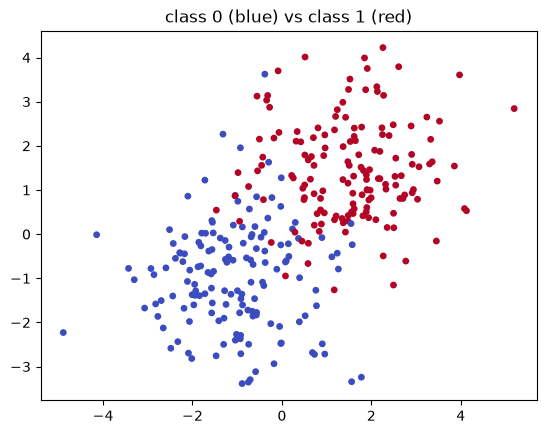

In [2]:
X2, y2 = make_blobs(n_samples=300, centers=[(-1, -1), (1.5, 1.5)], cluster_std=1.2, random_state=SEED)

plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", s=15)
plt.title("class 0 (blue) vs class 1 (red)")
plt.show()

## 2. The sigmoid squeezes any number into (0, 1)
Large positive score → probability near 1, large negative → near 0, score 0 → exactly 0.5.

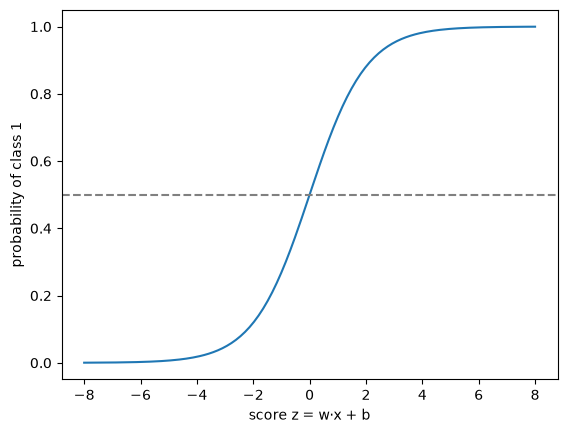

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls="--", c="gray")
plt.xlabel("score z = w·x + b")
plt.ylabel("probability of class 1")
plt.show()

## 3. Fit the model
Training finds the weights `w` and bias `b`. We can recompute the probability by hand — it is just sigmoid of a weighted sum.

In [4]:
clf2 = LogisticRegression().fit(X2, y2)
w, b = clf2.coef_[0], clf2.intercept_[0]
print("weights:", w.round(3), "bias:", round(b, 3))

point = np.array([[0.5, 0.0]])
print("sklearn:", clf2.predict_proba(point)[0, 1].round(4))
print("by hand:", sigmoid(point @ w + b)[0].round(4))

weights: [1.702 1.484] bias: -0.787
sklearn: 0.5162
by hand: 0.5162


## 4. Decision boundary and threshold
With threshold 0.5 the boundary is the line where `w·x + b = 0`. A higher threshold says “class 1” only when the model is more sure: fewer false alarms, more misses.

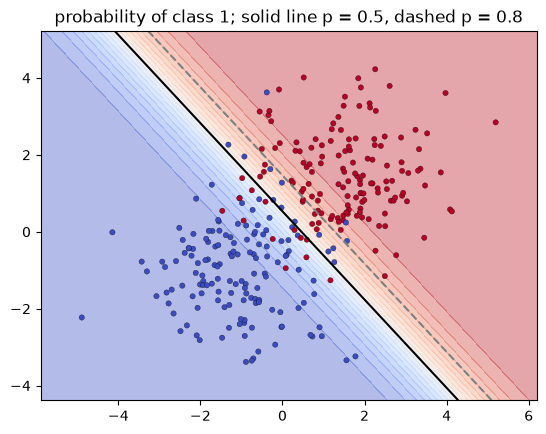

threshold 0.5: false alarms 14, misses 13
threshold 0.8: false alarms 3, misses 22


In [5]:
def plot_boundary(clf, X, y):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    p = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    plt.contourf(xx, yy, p, levels=20, cmap="coolwarm", alpha=0.4)
    plt.contour(xx, yy, p, levels=[0.5, 0.8], colors=["black", "gray"], linestyles=["-", "--"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15, edgecolor="k", linewidth=0.2)
    plt.title("probability of class 1; solid line p = 0.5, dashed p = 0.8")
    plt.show()


def errors_at(threshold, clf, X, y):
    pred = (clf.predict_proba(X)[:, 1] >= threshold).astype(int)
    false_alarms = int(((pred == 1) & (y == 0)).sum())
    misses = int(((pred == 0) & (y == 1)).sum())
    print(f"threshold {threshold}: false alarms {false_alarms}, misses {misses}")


plot_boundary(clf2, X2, y2)
errors_at(0.5, clf2, X2, y2)
errors_at(0.8, clf2, X2, y2)

# Part 2 — multiclass: MNIST digits
## 5. Data
The same MNIST digits as in the Digit Recognizer notebook (from OpenML, no login needed).

In [6]:
def load_mnist(n=42000):
    X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="liac-arff")
    return X[:n].astype(np.float32) / 255.0, y[:n].astype(int)


def split(X, y, val_fraction=0.2, seed=SEED):
    idx = np.random.default_rng(seed).permutation(len(X))
    n_val = int(len(X) * val_fraction)
    return X[idx[n_val:]], y[idx[n_val:]], X[idx[:n_val]], y[idx[:n_val]]


X_train, y_train, X_val, y_val = split(*load_mnist())
print("train:", X_train.shape, "validation:", X_val.shape)

train: (33600, 784) validation: (8400, 784)


## 6. Softmax: ten scores → ten probabilities
The model has one weight vector per digit (10 × 784 weights). Each digit gets a score; softmax makes them positive and summing to 1.

In [7]:
def softmax(scores):
    e = np.exp(scores - scores.max(axis=1, keepdims=True))  # subtract max for numerical stability
    return e / e.sum(axis=1, keepdims=True)


clf = LogisticRegression(max_iter=300).fit(X_train, y_train)
scores = X_val[:1] @ clf.coef_.T + clf.intercept_
print("by hand:", softmax(scores).round(3))
print("sklearn:", clf.predict_proba(X_val[:1]).round(3))
print("true digit:", y_val[0], "| predicted:", clf.predict(X_val[:1])[0])

by hand: [[0.    0.    0.002 0.005 0.921 0.023 0.001 0.002 0.002 0.045]]
sklearn: [[0.    0.    0.002 0.005 0.921 0.023 0.001 0.002 0.002 0.045]]
true digit: 4 | predicted: 4


## 7. How good is it?
Compared with the nearest-centroid baseline from the Digit Recognizer notebook.

In [8]:
def nearest_centroid_accuracy(X_tr, y_tr, X_va, y_va):
    centroids = np.stack([X_tr[y_tr == d].mean(axis=0) for d in range(10)])
    pred = ((X_va[:, None, :] - centroids[None]) ** 2).sum(axis=2).argmin(axis=1)
    return (pred == y_va).mean()


print(f"nearest centroid:    {nearest_centroid_accuracy(X_train, y_train, X_val, y_val):.4f}")
print(f"logistic regression: {clf.score(X_val, y_val):.4f}")

nearest centroid:    0.8049
logistic regression: 0.9174


## 8. One-vs-rest: ten binary models instead of one softmax
Another way to do multiclass: train one binary “this digit or not” model per digit and pick the most confident.

In [9]:
ovr = OneVsRestClassifier(LogisticRegression(max_iter=300)).fit(X_train, y_train)
print(f"softmax (multinomial): {clf.score(X_val, y_val):.4f}")
print(f"one-vs-rest:           {ovr.score(X_val, y_val):.4f}")

softmax (multinomial): 0.9174
one-vs-rest:           0.9120


## 9. What did the model learn? Weights as images
Each digit's 784 weights drawn as a 28×28 picture: red pixels vote *for* the digit, blue *against*. Stronger regularisation (smaller `C`) gives smoother, more readable templates — and a different accuracy.

C=1.0     train 0.9435  validation 0.9174
C=0.01    train 0.9142  validation 0.9068
C=0.0001  train 0.8298  validation 0.8233


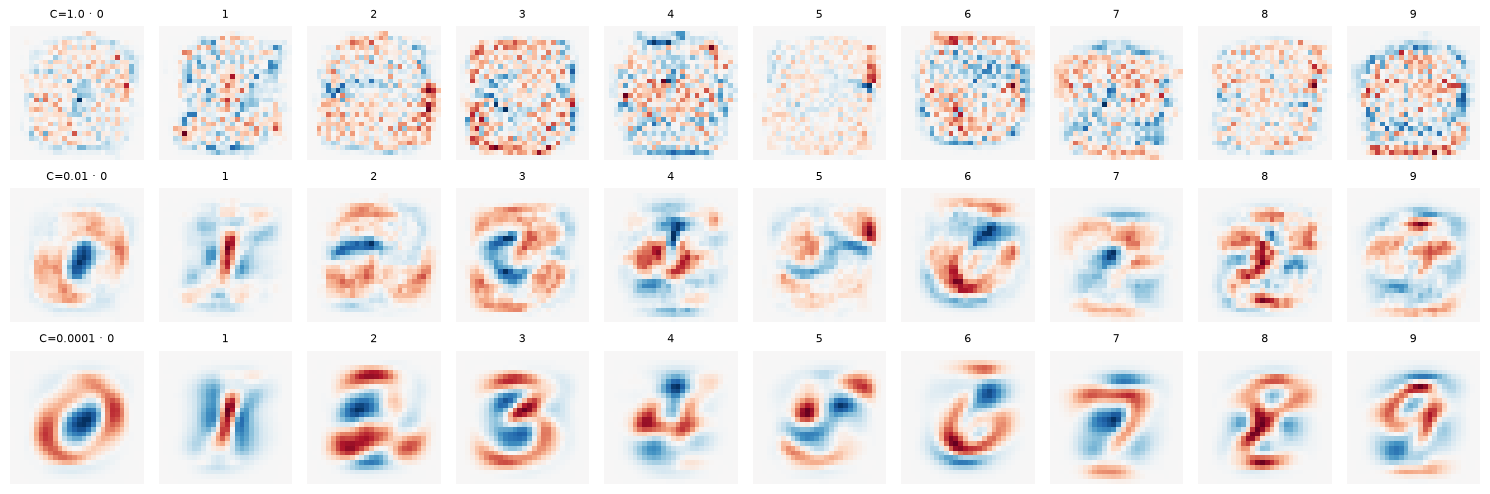

In [10]:
def plot_weights(models):
    fig, axes = plt.subplots(len(models), 10, figsize=(15, 1.7 * len(models)))
    for row, (C, model) in enumerate(models.items()):
        for d in range(10):
            w = model.coef_[d].reshape(28, 28)
            m = np.abs(w).max()
            axes[row, d].imshow(w, cmap="RdBu_r", vmin=-m, vmax=m)
            axes[row, d].set_title(f"C={C} · {d}" if d == 0 else str(d), fontsize=8)
            axes[row, d].axis("off")
    plt.tight_layout()
    plt.show()


models = {C: LogisticRegression(C=C, max_iter=300).fit(X_train, y_train) for C in (1.0, 0.01, 0.0001)}
for C, model in models.items():
    print(f"C={C:<7} train {model.score(X_train, y_train):.4f}  validation {model.score(X_val, y_val):.4f}")
plot_weights(models)

## Takeaways

- Logistic regression = **linear score + sigmoid** (binary) or **+ softmax** (multiclass).
- The output is a **probability**; the **threshold** turns it into a decision and can be tuned.
- On MNIST it beats the nearest-centroid baseline by about 11 points, but it is still linear: one template per digit.
- **Next:** a neural network adds a hidden layer between pixels and scores — see the PyTorch notebook.